# Rossmann Store Sales – Exploratory Data Analysis

In [15]:
# Works both in Google Colab and locally (after git clone)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/rossmann-sales-analysis/'
except ImportError:
    BASE_DIR = '../'

DATA_DIR = BASE_DIR + 'data/'
FIG_DIR = BASE_DIR + 'figures/'

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

df = pd.read_parquet(DATA_DIR + 'train_clean.parquet')

df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
print(df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(844338, 19)


                  mean   count
DayOfWeek                     
1          8216.252259  137557
2          7088.409086  143955
3          6728.786679  141922
4          6768.214973  134626
5          7073.034133  138633
6          5875.084935  144052
7          8224.723908    3593


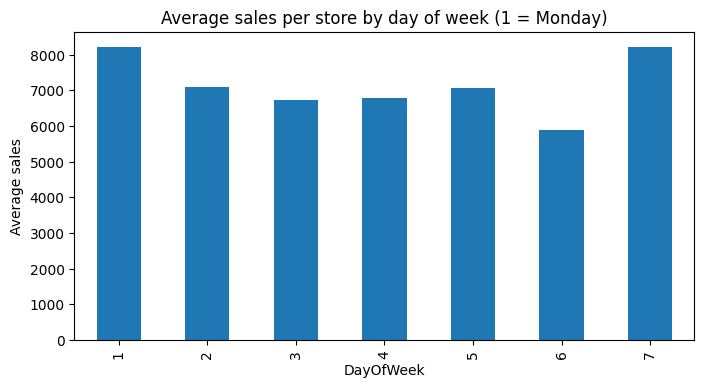

In [16]:
dow = df.groupby('DayOfWeek')['Sales'].agg(['mean', 'count'])
print(dow)

dow['mean'].plot(kind='bar', figsize=(8, 4),
                 title='Average sales per store by day of week (1 = Monday)')
plt.ylabel('Average sales')
plt.show()

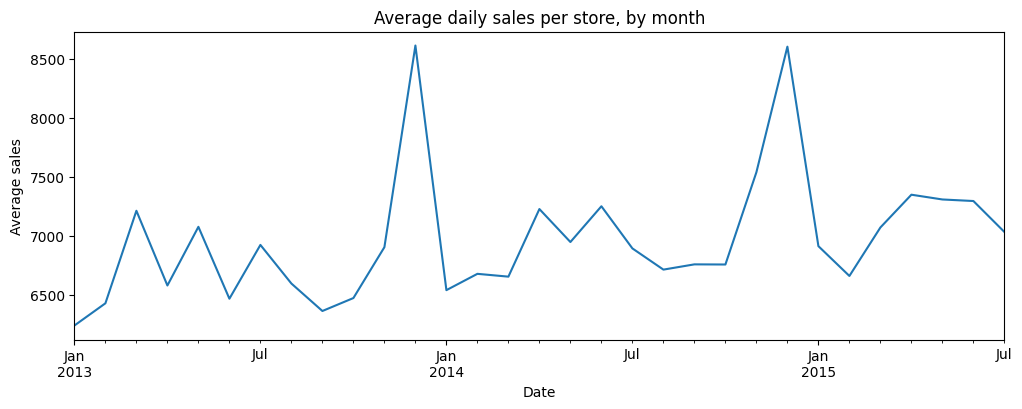

In [17]:
monthly = df.set_index('Date')['Sales'].resample('ME').mean()
monthly.plot(figsize=(12, 4), title='Average daily sales per store, by month')
plt.ylabel('Average sales')
plt.show()

In [18]:
sunday_stores = df.loc[df['DayOfWeek'] == 7, 'Store'].unique()
print('Stores ever open on Sunday:', len(sunday_stores))

# Same stores, all days of the week
df[df['Store'].isin(sunday_stores)].groupby('DayOfWeek')['Sales'].mean().round(0)

Stores ever open on Sunday: 33


,Sales
DayOfWeek,
1,9488.0
2,8578.0
3,8381.0
4,8485.0
5,8865.0
6,7021.0
7,8225.0


In [19]:
sun = df[df['Store'].isin(sunday_stores)]
per_store = sun.groupby(['Store', sun['DayOfWeek'] == 7])['Sales'].mean().unstack()
print('Stores where the Sunday average is below the Mon–Sat average:',
      (per_store[True] < per_store[False]).sum(), 'of', len(per_store))

Stores where the Sunday average is below the Mon–Sat average: 20 of 33


**Day of week:** Most stores are closed on Sundays (German shop-closing laws).
Only 33 stores open on Sundays. Within these stores, Sunday sales are on average lower than on weekdays (this holds for
20 of the 33 stores; in the others Sunday is the stronger day)

Monday has the highest sales even in Sunday-open stores, so demand shifted from
Sunday does not fully explain it. Next step: check whether promotions are unevenly
distributed across weekdays.

This data cannot tell us whether opening more stores on Sundays would increase sales: Sunday-open stores are not comparable to other stores, and part of Sunday sales may simply be shifted from other weekdays.

**Monthly trend:** Strong peak in December (Christmas) in both years, followed by
a drop in January. Overall, sales slightly increase over time.

In [20]:
promo_by_day = df.groupby('DayOfWeek')['Promo'].mean().round(2)
print('Share of days with Promo, by day of week:')
print(promo_by_day)

Share of days with Promo, by day of week:
DayOfWeek
1    0.56
2    0.54
3    0.54
4    0.55
5    0.52
6    0.00
7    0.00
Name: Promo, dtype: float64


In [21]:
by_day_promo = df.groupby(['DayOfWeek', 'Promo'])['Sales'].mean().unstack().round(0)
by_day_promo.columns = ['No Promo', 'Promo']
by_day_promo

,No Promo,Promo
DayOfWeek,,
1,6223.0,9773.0
2,5716.0,8278.0
3,5618.0,7686.0
4,5751.0,7599.0
5,6344.0,7744.0
6,5875.0,NaN
7,8225.0,NaN


In [22]:
by_day_promo['Uplift %'] = ((by_day_promo['Promo'] / by_day_promo['No Promo'] - 1) * 100).round(1)
by_day_promo

,No Promo,Promo,Uplift %
DayOfWeek,,,
1,6223.0,9773.0,57.0
2,5716.0,8278.0,44.8
3,5618.0,7686.0,36.8
4,5751.0,7599.0,32.1
5,6344.0,7744.0,22.1
6,5875.0,NaN,NaN
7,8225.0,NaN,NaN


**Promotions and weekdays:** Promotions run only Mon–Fri. Without promotions, sales are
similar across all days from Monday to Saturday (Mon and Fri slightly higher, Sat slightly lower).

The promo uplift decreases during the week: from about +57% on Monday to +22% on Friday.
The Monday peak is therefore a combination of Monday and promotion (interaction effect).
Possible explanation (hypothesis): promotions start on Mondays and customers react early.

Consequence for modelling: control for day of week and include a DayOfWeek × Promo interaction.

## Store type and assortment

In [23]:
for col in ['StoreType', 'Assortment']:
    summary = df.groupby(col).agg(
        stores=('Store', 'nunique'),
        avg_sales=('Sales', 'mean'),
        avg_customers=('Customers', 'mean')
    ).round(0)
    summary['sales_per_customer'] = (summary['avg_sales'] / summary['avg_customers']).round(2)
    display(summary)

,stores,avg_sales,avg_customers,sales_per_customer
StoreType,,,,
a,602,6926.0,795.0,8.71
b,17,10233.0,2022.0,5.06
c,148,6933.0,816.0,8.50
d,348,6822.0,606.0,11.26


,stores,avg_sales,avg_customers,sales_per_customer
Assortment,,,,
a,593,6622.0,748.0,8.85
b,9,8643.0,2068.0,4.18
c,513,7301.0,752.0,9.71


In [24]:
store_level = df.groupby('Store')[['StoreType', 'Assortment']].first()

print('Number of stores by StoreType and Assortment:')
display(pd.crosstab(store_level['StoreType'], store_level['Assortment']))

print('StoreType of the 33 Sunday-open stores:')
print(store_level.loc[sunday_stores, 'StoreType'].value_counts())

Number of stores by StoreType and Assortment:


Assortment,a,b,c
StoreType,,,
a,381,0,221
b,7,9,1
c,77,0,71
d,128,0,220


StoreType of the 33 Sunday-open stores:
StoreType
b    17
a    13
d     3
Name: count, dtype: int64


**Store type and assortment:** Store types a, c and d have similar average sales, but
different structures: type d has fewer customers but larger baskets. Type b (only 17 stores)
has very high traffic (about 2.5–3x more customers than other types) and small baskets, which fits
high-traffic locations such as train stations.

Stores with extended assortment (c) sell more than basic stores (a), mainly through
larger baskets, not more customers. This is a correlation; location may also play a role.

All 17 type-b stores are open on Sundays (17 of the 33 Sunday-open stores), and
assortment b exists only in type-b stores. This strongly supports the idea that type b
represents special high-traffic locations. As a result, the effect of store type b
cannot be separated from Sunday opening and location.

Most type-d stores (220 of 348) have an extended assortment, so part of their larger
basket size may come from assortment rather than store type. Both variables will be
included together in the model.

Groups with very few stores (StoreType b, Assortment b) should be interpreted with caution.

## Holidays

In [25]:
holiday = df.groupby('StateHoliday').agg(
    days=('Sales', 'size'),
    stores=('Store', 'nunique'),
    avg_sales=('Sales', 'mean')
).round(0)
holiday

,days,stores,avg_sales
StateHoliday,,,
0,843428,1115,6954.0
a,694,156,8487.0
b,145,32,9888.0
c,71,20,9744.0


In [26]:
school = df.groupby(['SchoolHoliday', 'Promo'])['Sales'].mean().unstack().round(0)
school.columns = ['No Promo', 'Promo']
school.index = ['No school holiday', 'School holiday']
school

,No Promo,Promo
No school holiday,5877.0,8200.0
School holiday,6166.0,8341.0


**Holidays:** Only a few stores open on public holidays (156 on regular public holidays,
32 at Easter, 20 at Christmas). Their high average sales reflect which stores are open
(selection bias, as with Sundays), not higher demand.

School holidays have only a small positive association with sales (about +5% without
promo, +2% with promo). Part of this may be seasonal, because school holidays fall
mainly in summer and around Christmas.

## Competition

In [27]:
# Distance is a store attribute, so we analyse at store level (one row per store)
store_avg = df.groupby('Store').agg(
    avg_sales=('Sales', 'mean'),
    avg_customers=('Customers', 'mean'),
    comp_dist=('CompetitionDistance', 'first')
)

store_avg['dist_group'] = pd.qcut(store_avg['comp_dist'], q=5)
store_avg.groupby('dist_group', observed=True).agg(
    stores=('avg_sales', 'size'),
    avg_sales=('avg_sales', 'mean'),
    avg_customers=('avg_customers', 'mean')
).round(0)

,stores,avg_sales,avg_customers
dist_group,,,
"(19.999, 520.0]",226,7554.0,954.0
"(520.0, 1600.0]",221,6784.0,796.0
"(1600.0, 3450.0]",221,6720.0,706.0
"(3450.0, 8666.0]",221,6798.0,663.0
"(8666.0, 75860.0]",223,6825.0,653.0


**Competition:** Stores with the closest competitor (< 520 m) have the highest sales and
the most customers. Beyond that, sales are similar across distance groups, while the number
of customers decreases and basket size increases with distance.

This does not mean that nearby competitors increase sales. Competitors cluster in busy
urban areas, so short distance is likely a proxy for location and foot traffic
(confounding). Analysis is done at store level, because distance is a store attribute.

Possible extension: compare sales of the same store before and after a competitor
opened (using `CompetitionOpenSince`), which would be closer to a causal effect.

## Key findings

1. **Selection bias:** Sundays and public holidays show high average sales mainly because
   a small, special group of stores is open on those days.
2. **Confounding by promotions:** Promotions run only Mon–Fri. The low Saturday average is
   mainly caused by the absence of promotions.
3. **Interaction:** The promo uplift decreases during the week (about +57% on Monday,
   +22% on Friday).
4. **Seasonality:** Strong December peak, drop in January, slight upward trend over time.
5. **Store structure:** Store types reach similar sales through different paths (more
   customers vs. larger baskets). Type b stores are special high-traffic locations.
6. **Location as confounder:** Short distance to competitors is associated with higher
   sales, likely because both reflect busy urban locations.

**Implications for modelling:** The promotion effect must be estimated while controlling
for day of week, season, holidays and store differences, including a
DayOfWeek × Promo interaction.